# Iteration 3: Ensembling and Statistical Significance

Notebooks 02/02b/03/04 each report a single UAR/accuracy point estimate per model on the
same ~371-window, 52-participant dataset. At this sample size, point-estimate
differences between models (0.32-0.44 UAR across the whole project) are routinely
inside sampling noise, so claiming "model X beats baseline" is not yet defensible.

This notebook:
1. Loads the saved `predictions.csv` from each earlier notebook (now including
   per-class `proba__<label>` columns) -- including the `handcrafted_baseline` models,
   which scored the best of any single model in the project (see notebook 02b) but were
   previously left out of the ensemble below.
2. Computes participant-level bootstrap confidence intervals for each model's UAR.
3. Builds a soft-vote ensemble -- cheap, since it only averages already-computed
   probabilities. We compare a few candidate component sets rather than assuming
   "more models is better": a kitchen-sink ensemble of all six models actually scores
   worse than a curated four-model one (see the component-set comparison below), because
   it dilutes the strong handcrafted models with the weaker 196-generic-feature and
   video-heavy ones.
4. Runs a paired bootstrap test to check whether the ensemble (or any single model)
   actually beats the naive 196-feature baseline, not just edges it out on a point
   estimate -- and separately, whether the ensemble beats the best *single* model, which
   is the more interesting question once you already have that model in hand.

Run notebooks 02b, 03, and 04 first (with `run_all_folds = True`) so their
`predictions.csv` files include the `proba__<label>` columns this notebook needs.


In [1]:
from pathlib import Path


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "dataset" / "README.md").exists():
            return candidate
    raise FileNotFoundError("Could not find the project root containing dataset/README.md.")


root = find_project_root(Path.cwd().resolve())
artifact_dir = root / "artifacts" / "ensemble"
artifact_dir.mkdir(parents=True, exist_ok=True)

n_boot = 2000
ci_level = 0.95
seed = 42

root


WindowsPath('C:/projects/DriverStateNet')

In [2]:
import sys

import pandas as pd

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import src.data_bootstrap as data_bootstrap
import src.evaluation as evaluation

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

LABELS = data_bootstrap.LABEL_ORDER
LABELS


['baseline', 'cognitive_distraction', 'alcohol_intoxication', 'combined']

## 1. Load predictions from each model

Only models evaluated with `run_all_folds = True` (so every model sees the full
371-window / 5-fold set) are comparable here. Models missing `proba__<label>` columns
(saved with an older version of `src/`, before this notebook was added) are skipped
with a warning rather than crashing -- rerun that model's notebook to include it.

In [3]:
CANDIDATE_PREDICTIONS = {
    "logistic_regression": artifact_dir.parent / "logreg_baseline" / "logistic_regression" / "predictions.csv",
    "linear_svm": artifact_dir.parent / "logreg_baseline" / "linear_svm" / "predictions.csv",
    "handcrafted_logistic_regression": artifact_dir.parent / "handcrafted_baseline" / "logistic_regression" / "predictions.csv",
    "handcrafted_linear_svm": artifact_dir.parent / "handcrafted_baseline" / "linear_svm" / "predictions.csv",
    "temporal_transformer": artifact_dir.parent / "temporal_transformer" / "all_folds" / "predictions.csv",
    "multimodal_tabular_only": artifact_dir.parent / "multimodal_fusion" / "all_folds" / "tabular_only" / "predictions.csv",
    "multimodal_fusion": artifact_dir.parent / "multimodal_fusion" / "all_folds" / "fusion" / "predictions.csv",
}

REQUIRED_COLUMNS = {"true_label", "pred_label", "participant_name", *[f"proba__{label}" for label in LABELS]}

model_predictions: dict[str, pd.DataFrame] = {}
for model_name, path in CANDIDATE_PREDICTIONS.items():
    if not path.exists():
        print(f"[skip] {model_name}: {path} not found (run that notebook with run_all_folds=True first)")
        continue
    frame = evaluation.load_predictions(path)
    missing = REQUIRED_COLUMNS - set(frame.columns)
    if missing:
        print(f"[skip] {model_name}: missing {sorted(missing)} -- rerun with the updated src/ to get probability columns")
        continue
    model_predictions[model_name] = frame
    print(f"[ok]   {model_name}: {len(frame)} rows, {frame['participant_name'].nunique()} participants")

model_predictions.keys()


[ok]   logistic_regression: 371 rows, 52 participants
[ok]   linear_svm: 371 rows, 52 participants
[ok]   handcrafted_logistic_regression: 371 rows, 52 participants
[ok]   handcrafted_linear_svm: 371 rows, 52 participants
[ok]   temporal_transformer: 371 rows, 52 participants
[ok]   multimodal_tabular_only: 371 rows, 52 participants
[ok]   multimodal_fusion: 371 rows, 52 participants


dict_keys(['logistic_regression', 'linear_svm', 'handcrafted_logistic_regression', 'handcrafted_linear_svm', 'temporal_transformer', 'multimodal_tabular_only', 'multimodal_fusion'])

## 2. Bootstrap confidence intervals per model

Resamples participants (not individual windows) with replacement, since windows from
the same participant are correlated. If two models' CIs overlap heavily, the point
estimates alone do not justify preferring one over the other.

In [4]:
ci_rows = []
for model_name, frame in model_predictions.items():
    result = evaluation.bootstrap_uar_ci(frame, labels=LABELS, n_boot=n_boot, ci=ci_level, seed=seed)
    ci_rows.append({"model_name": model_name, **result})

ci_table = pd.DataFrame(ci_rows).set_index("model_name").sort_values("uar", ascending=False)
ci_table.to_csv(artifact_dir / "bootstrap_ci.csv")
ci_table


,uar,ci_low,ci_high,ci_level,n_boot,n_groups
model_name,,,,,,
handcrafted_logistic_regression,0.439852,0.378528,0.501412,0.95,2000,52
handcrafted_linear_svm,0.417289,0.360544,0.478524,0.95,2000,52
temporal_transformer,0.390666,0.328152,0.463886,0.95,2000,52
linear_svm,0.376076,0.309835,0.447460,0.95,2000,52
logistic_regression,0.369665,0.294584,0.452122,0.95,2000,52
multimodal_tabular_only,0.358091,0.280816,0.443490,0.95,2000,52
multimodal_fusion,0.349035,0.290356,0.415924,0.95,2000,52


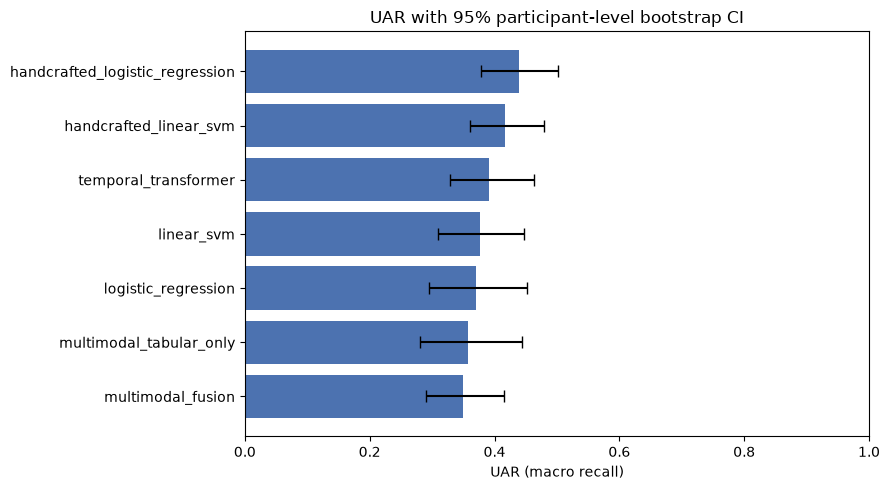

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
plot_table = ci_table.sort_values("uar")
errors = [
    (plot_table["uar"] - plot_table["ci_low"]).to_numpy(),
    (plot_table["ci_high"] - plot_table["uar"]).to_numpy(),
]
ax.barh(plot_table.index, plot_table["uar"], xerr=errors, capsize=4, color="#4C72B0")
ax.set_xlabel("UAR (macro recall)")
ax.set_title(f"UAR with {int(ci_level * 100)}% participant-level bootstrap CI")
ax.set_xlim(0.0, 1.0)
fig.tight_layout()
fig.savefig(artifact_dir / "bootstrap_ci.png", dpi=150)
plt.show()


## 3. Soft-vote ensemble

Averages per-class probabilities across a chosen set of models -- cheap, since it
reuses each model's already-saved predictions with no retraining.

The original version of this notebook only ever tried one component set
(`linear_svm + temporal_transformer + multimodal_tabular_only + multimodal_fusion`),
which excluded the `handcrafted_baseline` models even though they scored best of
anything in the project. Below we compare a few candidate sets by 5-fold UAR and keep
the best one, instead of assuming a fixed set or "more models is better".

In [6]:
candidate_component_sets = {
    "original_no_handcrafted": ["linear_svm", "temporal_transformer", "multimodal_tabular_only", "multimodal_fusion"],
    "handcrafted_pair": ["handcrafted_logistic_regression", "handcrafted_linear_svm"],
    "handcrafted_lr_plus_transformer": ["handcrafted_logistic_regression", "temporal_transformer"],
    "top4": ["handcrafted_logistic_regression", "handcrafted_linear_svm", "temporal_transformer", "multimodal_tabular_only"],
    "all_models": list(model_predictions.keys()),
}

component_set_rows = []
for set_name, members in candidate_component_sets.items():
    available = [name for name in members if name in model_predictions]
    if len(available) < 2:
        continue
    result = evaluation.soft_vote_ensemble({name: model_predictions[name] for name in available}, labels=LABELS)
    component_set_rows.append(
        {
            "component_set": set_name,
            "members": "+".join(available),
            "uar": float(result["overall_metrics"]["uar"]),
        }
    )

component_set_table = pd.DataFrame(component_set_rows).set_index("component_set").sort_values("uar", ascending=False)
component_set_table.to_csv(artifact_dir / "ensemble_component_set_comparison.csv")
display(component_set_table)

ensemble_components = candidate_component_sets[component_set_table.index[0]]
ensemble_components = [name for name in ensemble_components if name in model_predictions]
print("Best component set:", component_set_table.index[0], "->", ensemble_components)

ensemble_result = None
if len(ensemble_components) >= 2:
    ensemble_result = evaluation.soft_vote_ensemble(
        {name: model_predictions[name] for name in ensemble_components},
        labels=LABELS,
    )
    ensemble_result["predictions"].to_csv(artifact_dir / "ensemble_predictions.csv", index=False)
    ensemble_result["overall_metrics"].to_csv(artifact_dir / "ensemble_overall_metrics.csv", header=["value"])
    ensemble_result["overall_confusion"].to_csv(artifact_dir / "ensemble_overall_confusion.csv")
    ensemble_result["per_class_report"].to_csv(artifact_dir / "ensemble_per_class_report.csv")
    display(ensemble_result["overall_metrics"].to_frame("value"))
    display(ensemble_result["per_class_report"])
else:
    print("Need at least two models with matching predictions to build an ensemble.")


,members,uar
component_set,,
top4,handcrafted_logistic_regression+handcrafted_li...,0.478033
handcrafted_lr_plus_transformer,handcrafted_logistic_regression+temporal_trans...,0.470372
handcrafted_pair,handcrafted_logistic_regression+handcrafted_li...,0.445289
all_models,logistic_regression+linear_svm+handcrafted_log...,0.420098
original_no_handcrafted,linear_svm+temporal_transformer+multimodal_tab...,0.416270


Best component set: top4 -> ['handcrafted_logistic_regression', 'handcrafted_linear_svm', 'temporal_transformer', 'multimodal_tabular_only']


,value
model_name,ensemble(handcrafted_logistic_regression+handc...
uar,0.478033
precision_macro,0.45436
recall_macro,0.478033
f1_macro,0.458901
accuracy,0.528302
num_samples,371
num_models,4
component_models,handcrafted_logistic_regression+handcrafted_li...


,precision,recall,f1,support
baseline,0.659722,0.641892,0.650685,148
cognitive_distraction,0.596639,0.482993,0.533835,147
alcohol_intoxication,0.295455,0.351351,0.320988,37
combined,0.265625,0.435897,0.330097,39


In [7]:
if ensemble_result is not None:
    ensemble_ci = evaluation.bootstrap_uar_ci(
        ensemble_result["predictions"], labels=LABELS, n_boot=n_boot, ci=ci_level, seed=seed
    )
    ci_table = pd.concat(
        [ci_table, pd.DataFrame([{"model_name": "ensemble", **ensemble_ci}]).set_index("model_name")]
    ).sort_values("uar", ascending=False)
    ci_table.to_csv(artifact_dir / "bootstrap_ci.csv")
ci_table

,uar,ci_low,ci_high,ci_level,n_boot,n_groups
model_name,,,,,,
ensemble,0.478033,0.402588,0.561364,0.95,2000,52
handcrafted_logistic_regression,0.439852,0.378528,0.501412,0.95,2000,52
handcrafted_linear_svm,0.417289,0.360544,0.478524,0.95,2000,52
temporal_transformer,0.390666,0.328152,0.463886,0.95,2000,52
linear_svm,0.376076,0.309835,0.447460,0.95,2000,52
logistic_regression,0.369665,0.294584,0.452122,0.95,2000,52
multimodal_tabular_only,0.358091,0.280816,0.443490,0.95,2000,52
multimodal_fusion,0.349035,0.290356,0.415924,0.95,2000,52


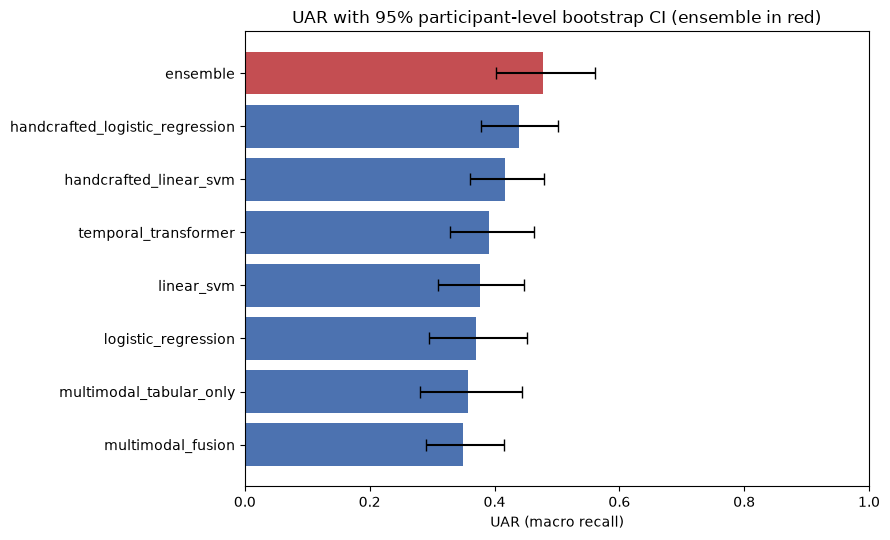

In [8]:
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_table = ci_table.sort_values("uar")
errors = [
    (plot_table["uar"] - plot_table["ci_low"]).to_numpy(),
    (plot_table["ci_high"] - plot_table["uar"]).to_numpy(),
]
colors = ["#C44E52" if name == "ensemble" else "#4C72B0" for name in plot_table.index]
ax.barh(plot_table.index, plot_table["uar"], xerr=errors, capsize=4, color=colors)
ax.set_xlabel("UAR (macro recall)")
ax.set_title(f"UAR with {int(ci_level * 100)}% participant-level bootstrap CI (ensemble in red)")
ax.set_xlim(0.0, 1.0)
fig.tight_layout()
fig.savefig(artifact_dir / "bootstrap_ci.png", dpi=150)
plt.show()

## 4. Does anything actually beat the baseline? (paired significance test)

Compares each candidate against `linear_svm` (the strongest classical baseline) with a
paired bootstrap over participants: both models are scored on the same resampled
participants each draw, and `significant=True` only when the 95% CI of the UAR
difference excludes zero. This is the bar that should be cleared before claiming a
result "beats baselines" -- a positive point-estimate delta on its own is not enough
at this sample size.

In [9]:
baseline_name = "linear_svm"
comparison_targets = [name for name in model_predictions if name != baseline_name]
if ensemble_result is not None:
    model_predictions_with_ensemble = {**model_predictions, "ensemble": ensemble_result["predictions"]}
    comparison_targets.append("ensemble")
else:
    model_predictions_with_ensemble = model_predictions

significance_rows = []
if baseline_name in model_predictions:
    for target in comparison_targets:
        result = evaluation.paired_bootstrap_delta(
            model_predictions_with_ensemble[target],
            model_predictions[baseline_name],
            model_a_name=target,
            model_b_name=baseline_name,
            labels=LABELS,
            n_boot=n_boot,
            ci=ci_level,
            seed=seed,
        )
        significance_rows.append(result)
else:
    print(f"Baseline '{baseline_name}' predictions not loaded -- cannot run significance tests.")

significance_table = pd.DataFrame(significance_rows).set_index("model_a").sort_values("delta", ascending=False)
significance_table.to_csv(artifact_dir / "significance_vs_baseline.csv")
significance_table


,model_b,uar_a,uar_b,delta,ci_low,ci_high,ci_level,p_value,significant,n_boot,n_groups
model_a,,,,,,,,,,,
ensemble,linear_svm,0.478033,0.376076,0.101958,0.033829,0.170210,0.95,0.004,True,2000,52
handcrafted_logistic_regression,linear_svm,0.439852,0.376076,0.063776,0.008849,0.116893,0.95,0.025,True,2000,52
handcrafted_linear_svm,linear_svm,0.417289,0.376076,0.041213,-0.025613,0.104559,0.95,0.221,False,2000,52
temporal_transformer,linear_svm,0.390666,0.376076,0.014590,-0.076114,0.106846,0.95,0.755,False,2000,52
logistic_regression,linear_svm,0.369665,0.376076,-0.006410,-0.041980,0.027149,0.95,0.712,False,2000,52
multimodal_tabular_only,linear_svm,0.358091,0.376076,-0.017984,-0.088810,0.062740,0.95,0.657,False,2000,52
multimodal_fusion,linear_svm,0.349035,0.376076,-0.027041,-0.099530,0.049175,0.95,0.446,False,2000,52


## 4b. Does the ensemble beat the best *single* model?

Beating the naive 196-feature baseline is a low bar. The more interesting question,
once `handcrafted_logistic_regression` is already the strongest single model in the
project, is whether ensembling it with anything else is actually worth the added
complexity -- or just a point-estimate wobble.

In [10]:
best_single_name = "handcrafted_logistic_regression"
vs_best_single = None
if ensemble_result is not None and best_single_name in model_predictions:
    vs_best_single = evaluation.paired_bootstrap_delta(
        ensemble_result["predictions"],
        model_predictions[best_single_name],
        model_a_name="ensemble",
        model_b_name=best_single_name,
        labels=LABELS,
        n_boot=n_boot,
        ci=ci_level,
        seed=seed,
    )
    pd.Series(vs_best_single).to_csv(artifact_dir / "significance_vs_best_single_model.csv", header=["value"])
    display(pd.Series(vs_best_single).to_frame("value"))
else:
    print(f"'{best_single_name}' predictions or ensemble_result not available -- skipping this comparison.")

,value
model_a,ensemble
model_b,handcrafted_logistic_regression
uar_a,0.478033
uar_b,0.439852
delta,0.038181
ci_low,-0.019914
ci_high,0.099758
ci_level,0.95
p_value,0.213
significant,False


## 5. Summary

Only rows with `significant == True` and a positive `delta` represent a defensible
improvement over `linear_svm` at this sample size -- everything else is a point-estimate
difference that a paired bootstrap could not distinguish from noise.

In [11]:
summary = significance_table[["uar_a", "uar_b", "delta", "ci_low", "ci_high", "p_value", "significant"]]
summary = summary.rename(columns={"uar_a": "uar", "uar_b": "baseline_uar"})
summary.to_csv(artifact_dir / "summary.csv")
summary


,uar,baseline_uar,delta,ci_low,ci_high,p_value,significant
model_a,,,,,,,
ensemble,0.478033,0.376076,0.101958,0.033829,0.170210,0.004,True
handcrafted_logistic_regression,0.439852,0.376076,0.063776,0.008849,0.116893,0.025,True
handcrafted_linear_svm,0.417289,0.376076,0.041213,-0.025613,0.104559,0.221,False
temporal_transformer,0.390666,0.376076,0.014590,-0.076114,0.106846,0.755,False
logistic_regression,0.369665,0.376076,-0.006410,-0.041980,0.027149,0.712,False
multimodal_tabular_only,0.358091,0.376076,-0.017984,-0.088810,0.062740,0.657,False
multimodal_fusion,0.349035,0.376076,-0.027041,-0.099530,0.049175,0.446,False
